# k-SAT unit-propagation trace exploration

Random k-SAT instances solved with a textbook DPLL unit-propagation solver
(most-constrained-variable branching, chronological backtracking,
`spin_gnn/ksat.py`), with the solver's execution trace emitted as a sequence
of `{-1,0,1}`-valued vector tokens (current variable assignment, then every
currently non-trivial clause, at each step the assignment changes). A causal
transformer (`spin_gnn/sat_transformer.py`) is trained via next-token
prediction over these traces, to see whether attention alone can learn to
reproduce unit-propagation/backtracking dynamics.

See the "k-SAT unit-propagation trace exploration" section of `README.md`
for the full encoding spec. This notebook: (1) runs the correctness test
suite live, (2) loads/visualizes unit-propagation statistics and token
covariance across thousands of random instances, (3) reports a `(d_model,
nhead)` hyperparameter sweep at 10,000 training instances, (3b) follows up
on the "was single-head attention the bottleneck?" hypothesis with a
dedicated head-count scan at the previously-best width, (3c) follows up
further with a depth/MLP-width scan (`num_layers`, `dim_feedforward`) at the
best `(d_model, nhead)` found so far, (3d) follows up once more with a
low-rank-attention scan that decouples head count from Q/K projection rank
(`qk_dim`), and (4) lets you load the resulting checkpoint and explore it
interactively -- human-readable dataset examples, model-generated traces
rendered step-by-step against the true solver trace side by side -- without
retraining.

In [1]:
import json
import os
from pathlib import Path

import matplotlib.pyplot as plt
import numpy as np
import pandas as pd

REPO_ROOT = Path("/home/users/hshunt/spin_gnn")
SCRATCH = Path(os.environ["SCRATCH"])
SAT_STATS_CSV = SCRATCH / "spin_gnn" / "sat_stats_big" / "sat_stats_n24_k3_a4.2.csv"
SWEEP_DIR = SCRATCH / "spin_gnn" / "sat_hparam_sweep"

# Same validated palette as notebooks/results.ipynb (dataviz skill's
# references/palette.md), reused here for visual consistency across this
# repo's result notebooks.
INK = {
    "surface": "#fcfcfb",
    "primary": "#0b0b0b",
    "secondary": "#52514e",
    "muted": "#898781",
    "grid": "#e1e0d9",
    "axis": "#c3c2b7",
}
CATEGORICAL = ["#2a78d6", "#eb6834", "#1baf7a"]  # blue, orange, aqua -- fixed order
OUTCOME_COLOR = {1: CATEGORICAL[0], 0: CATEGORICAL[1]}  # satisfiable=1 blue, unsatisfiable=0 orange

# Diverging pair for covariance (two hues + a neutral midpoint, not a
# rainbow) built from the same fixed categorical identities: orange = the
# negative pole, blue = the positive pole, the surface's own ink-neutral at
# the midpoint.
from matplotlib.colors import LinearSegmentedColormap
DIVERGING_CMAP = LinearSegmentedColormap.from_list(
    "orange_blue_diverging", [CATEGORICAL[1], INK["grid"], CATEGORICAL[0]]
)

plt.rcParams["font.family"] = "sans-serif"


def style_axis(ax):
    ax.set_facecolor(INK["surface"])
    ax.spines["top"].set_visible(False)
    ax.spines["right"].set_visible(False)
    ax.spines["left"].set_color(INK["axis"])
    ax.spines["bottom"].set_color(INK["axis"])
    ax.tick_params(colors=INK["muted"])
    ax.grid(True, color=INK["grid"], linewidth=0.8, alpha=0.9)
    ax.set_axisbelow(True)
    ax.title.set_color(INK["primary"])
    ax.xaxis.label.set_color(INK["secondary"])
    ax.yaxis.label.set_color(INK["secondary"])

## 1. Correctness: solver + transformer test suite

`tests/test_ksat_solver.py` cross-checks `solve_with_trace`'s
satisfiable/unsatisfiable verdict against brute-force enumeration on small
random instances, plus hand-crafted SAT/UNSAT cases and trace-encoding
invariants. `tests/test_sat_transformer_shapes.py` checks the causal mask
and the `generate_trace` autoregressive decoder. `tests/test_train_sat_transformer.py`
is a regression test for a real bug this session's hyperparameter sweep hit
(see the Notes section at the bottom). Run live rather than pasted from a
saved log, so this always reflects the current code.

In [2]:
!cd {REPO_ROOT} && python -m pytest tests/ -q

........

.

.

..

...

........

..

.                                               [100%]
=============================== warnings summary ===============================
tests/test_sat_transformer_shapes.py::test_generate_trace_stops_at_max_len
tests/test_train_sat_transformer.py::test_satisfying_completion_rate_skips_traces_longer_than_model_max_len
tests/test_transformer_shapes.py::test_forward_shape_and_backward
tests/test_transformer_shapes.py::test_find_matching_d_model_hits_target_closely
  /share/software/user/open/py-pytorch/2.4.1_py312/lib/python3.12/site-packages/torch/nn/modules/transformer.py:307: UserWarning: enable_nested_tensor is True, but self.use_nested_tensor is False because encoder_layer.self_attn.num_heads is odd
    warnings.warn(f"enable_nested_tensor is True, but self.use_nested_tensor is False because {why_not_sparsity_fast_path}")

-- Docs: https://docs.pytest.org/en/stable/how-to/capture-warnings.html


26 passed, 4 warnings in 5.57s


## 2. Unit-propagation / backtracking statistics

3,000 random 3-SAT instances at `n_vars=24`, `alpha=4.2` (near the classic
random-3-SAT satisfiability threshold, ~4.267), generated via
`scripts/slurm/sat_stats.sbatch` / `spin_gnn.sat_stats`.

In [3]:
stats_df = pd.read_csv(SAT_STATS_CSV)
sat_frac = stats_df["satisfiable"].mean()
print(f"{len(stats_df)} instances, n_vars={stats_df['n_vars'].iloc[0]}, "
      f"m_clauses={stats_df['m_clauses'].iloc[0]}, alpha={stats_df['alpha'].iloc[0]}")
print(f"satisfiable fraction: {sat_frac:.0%}")
stats_df.groupby("satisfiable")[
    ["num_decisions", "num_unit_props", "num_flips", "num_backtracks", "max_decision_depth", "num_tokens"]
].agg(["mean", "std"]).round(1)

3000 instances, n_vars=24, m_clauses=101, alpha=4.2
satisfiable fraction: 73%


num_decisions      num_unit_props       num_flips       \
                     mean  std           mean   std      mean  std   
satisfiable                                                          
0                    12.6  4.0          114.6  33.4      12.6  4.0   
1                     8.9  4.0           56.3  35.3       4.9  4.2   

            num_backtracks      max_decision_depth      num_tokens          
                      mean  std               mean  std       mean     std  
satisfiable                                                                 
0                     12.6  4.0                5.4  1.1     7163.1  1743.4  
1                      3.0  3.5                6.1  1.7     2983.2  2028.9

Distributions of the key solver-dynamics counters, split by outcome
(blue = satisfiable, orange = unsatisfiable). UNSAT instances need more
backtracking on average, since reaching UNSAT requires exhausting every
decision ever made -- `num_backtracks == num_decisions` exactly whenever an
instance is UNSAT, an invariant `tests/test_ksat_solver.py` checks
directly.

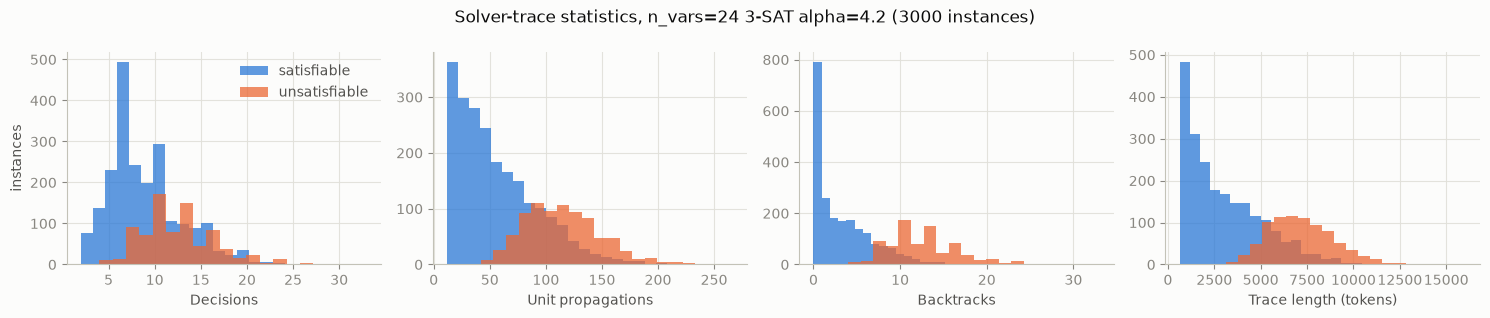

In [4]:
METRICS = [
    ("num_decisions", "Decisions"),
    ("num_unit_props", "Unit propagations"),
    ("num_backtracks", "Backtracks"),
    ("num_tokens", "Trace length (tokens)"),
]

fig, axes = plt.subplots(1, 4, figsize=(15, 3.2))
fig.patch.set_facecolor(INK["surface"])
for ax, (col, label) in zip(axes, METRICS):
    for outcome, name in [(1, "satisfiable"), (0, "unsatisfiable")]:
        vals = stats_df.loc[stats_df["satisfiable"] == outcome, col]
        ax.hist(vals, bins=20, color=OUTCOME_COLOR[outcome], alpha=0.75, label=name)
    ax.set_xlabel(label)
    style_axis(ax)
axes[0].set_ylabel("instances")
axes[0].legend(frameon=False, labelcolor=INK["secondary"])
fig.suptitle(f"Solver-trace statistics, n_vars=24 3-SAT alpha=4.2 ({len(stats_df)} instances)", color=INK["primary"])
fig.tight_layout()
plt.show()

### Token covariance

Empirical covariance of the `(n_vars+1)`-dim token vectors, pooling every
token (assignment and clause alike) from a sample of instances. Column/row
`n_vars` is the type dimension (-1=assignment, +1=clause) -- its variance and
its covariance with every variable column summarizes how a variable's
typical value differs between assignment-token rows and clause-token rows.
Diverging color (orange=negative, blue=positive) since covariance has a
sign; a neutral gray sits at zero.

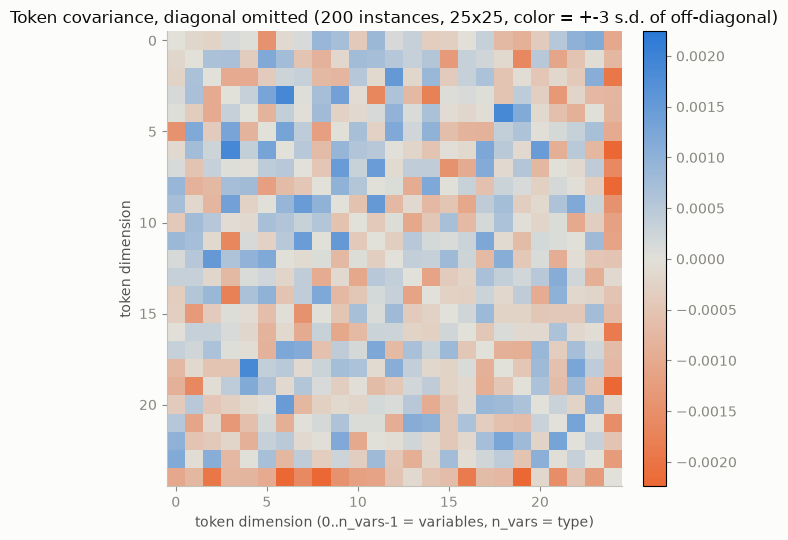

In [5]:
from spin_gnn.config import SATConfig
from spin_gnn.ksat import sample_random_ksat, solve_with_trace
from spin_gnn.sat_stats import token_covariance

# Cheap to regenerate on the fly (no pretraining needed) -- change this and
# rerun to explore a different sample size/instance family.
COV_N_INSTANCES = 200
COV_SEED_START = 0

cov_cfg = SATConfig(n_vars=24, k=3, alpha=4.2)
cov_traces = []
for i in range(COV_N_INSTANCES):
    rng = np.random.default_rng(COV_SEED_START + i)
    clauses = sample_random_ksat(cov_cfg, rng)
    cov_traces.append(solve_with_trace(clauses, cov_cfg.n_vars))

cov = token_covariance(cov_traces)

# The diagonal is pure per-dimension variance, an order of magnitude past
# every off-diagonal covariance -- a shared +-vmax color scale keyed off the
# full matrix (np.abs(cov).max()) saturates the diagonal and flattens every
# off-diagonal cell to the same near-zero color, showing nothing. Omit the
# diagonal from the plot entirely and scale color to the off-diagonal
# entries' own spread instead.
off_diag_mask = ~np.eye(cov.shape[0], dtype=bool)
off_diag_std = cov[off_diag_mask].std()
vmax = 3 * off_diag_std
cov_display = np.where(off_diag_mask, cov, np.nan)

cmap = DIVERGING_CMAP.copy()
cmap.set_bad(INK["grid"])

fig, ax = plt.subplots(figsize=(6.5, 5.5))
fig.patch.set_facecolor(INK["surface"])
im = ax.imshow(cov_display, cmap=cmap, vmin=-vmax, vmax=vmax)
ax.set_xlabel("token dimension (0..n_vars-1 = variables, n_vars = type)")
ax.set_ylabel("token dimension")
ax.set_title(
    f"Token covariance, diagonal omitted ({COV_N_INSTANCES} instances, "
    f"{cov.shape[0]}x{cov.shape[0]}, color = +-3 s.d. of off-diagonal)",
    color=INK["primary"],
)
style_axis(ax)
ax.grid(False)
cbar = fig.colorbar(im, ax=ax, fraction=0.046, pad=0.04)
cbar.ax.tick_params(colors=INK["muted"])
fig.tight_layout()
plt.show()

## 3. Hyperparameter sweep: does scale + width find >=90% accuracy?

The first (5-epoch, 40-instance, `d_model=32`) smoke run's per-dimension
accuracy plateaued almost immediately -- inconclusive on whether the
architecture *can* learn this task, or just that run was too small. This
sweep trains at `n_train_instances=10,000`, `n_val_instances=500`,
`epochs=15`, across a `d_model x nhead` grid
(`scripts/slurm/sat_hparam_sweep.sbatch`, `spin_gnn.sat_hparam_sweep`).

**Caveat, stated up front**: self-attention is `O(L^2)` in sequence length,
and trace length is heavy-tailed (section 2's histograms), so training used
`max_trace_tokens=2000` -- instances with longer traces are dropped before
batching (`spin_gnn.sat_dataset.SATTraceDataset`'s docstring explains why).
The dropped fraction is printed by each sweep job; the surviving instances
are systematically the *easier*, shorter-trace ones, which also shifts
`baseline_accuracy` (the majority-class-per-dimension baseline) upward
compared to the full instance distribution -- accuracy numbers below are
only meaningful relative to that shifted baseline, not against section 2's
full population.

In [6]:
from spin_gnn.aggregate_sat_sweep import aggregate

sweep_df = pd.DataFrame(aggregate(str(SWEEP_DIR)))
for col in ["d_model", "nhead", "num_layers", "dim_feedforward", "best_epoch"]:
    sweep_df[col] = sweep_df[col].astype(int)
for col in ["baseline_accuracy", "best_accuracy", "final_accuracy", "final_nll", "final_val_satisfying_completion_rate"]:
    sweep_df[col] = sweep_df[col].astype(float)

# Four sweep "generations" now share this directory: the original
# (d_model, nhead) grid, the nhead-only follow-up at d_model=256, the
# (num_layers, dim_feedforward) follow-up at fixed d_model=256/nhead=8,
# and the newest (nhead, qk_dim) low-rank-attention follow-up at fixed
# d_model=256/num_layers=4/dim_feedforward=1024. The qk sweep's tag also
# # contains "_L" (it reuses the mlp sweep's fixed num_layers/dim_feedforward),
# so split on "_qk" first -- checking "_L" alone would silently fold qk rows
# into mlp_grid.
qk_grid = sweep_df[sweep_df["checkpoint_dir"].str.contains("_qk")]
rest = sweep_df[~sweep_df["checkpoint_dir"].str.contains("_qk")]
base_grid = rest[~rest["checkpoint_dir"].str.contains("_L")]
mlp_grid = rest[rest["checkpoint_dir"].str.contains("_L")]

sweep_df[["d_model", "nhead", "baseline_accuracy", "best_accuracy", "best_epoch", "final_val_satisfying_completion_rate"]]

wrote /scratch/users/hshunt/spin_gnn/sat_hparam_sweep/aggregated.csv (51 rows, 51 source files)
best: d_model=256 nhead=16 best_accuracy=0.9440 (baseline=0.8905) checkpoint_dir=/scratch/users/hshunt/spin_gnn/sat_hparam_sweep/d0256_h16_L04_ff01024_qk0512


,d_model,nhead,baseline_accuracy,best_accuracy,best_epoch,final_val_satisfying_completion_rate
0,32,1,0.890455,0.890372,12,0.000000
1,32,2,0.890455,0.890371,0,0.000000
2,32,4,0.890455,0.890371,0,0.000000
3,64,1,0.890455,0.890372,8,0.000000
4,64,2,0.890455,0.890371,6,0.000000
5,64,4,0.890455,0.890371,4,0.000000
6,128,1,0.890455,0.890377,8,0.013986
7,128,2,0.890455,0.890371,3,0.020979
8,128,4,0.890455,0.890395,8,0.020979
9,256,1,0.890455,0.925871,13,0.000000


In [7]:
TARGET_ACCURACY = 0.90
hit_target = sweep_df[sweep_df["best_accuracy"] >= TARGET_ACCURACY]
best_row = sweep_df.loc[sweep_df["best_accuracy"].idxmax()]

if len(hit_target):
    print(f"{len(hit_target)}/{len(sweep_df)} configs reached >= {TARGET_ACCURACY:.0%} accuracy:")
    print(hit_target[["d_model", "nhead", "best_accuracy"]].to_string(index=False))
else:
    print(f"No config reached >= {TARGET_ACCURACY:.0%} accuracy in this sweep.")
print(f"\nBest: d_model={int(best_row['d_model'])} nhead={int(best_row['nhead'])} "
      f"num_layers={int(best_row['num_layers'])} dim_feedforward={int(best_row['dim_feedforward'])} "
      f"qk_dim={int(best_row['qk_dim'])} "
      f"best_accuracy={best_row['best_accuracy']:.4f} (baseline={best_row['baseline_accuracy']:.4f}, "
      f"lift over baseline={best_row['best_accuracy'] - best_row['baseline_accuracy']:+.4f}, "
      f"completion_rate={best_row['final_val_satisfying_completion_rate']:.4f})")

24/51 configs reached >= 90% accuracy:
 d_model  nhead  best_accuracy
     256      1       0.925871
     256      1       0.936219
     256      2       0.929504
     256      2       0.937715
     256      4       0.933504
     256      4       0.938606
     256      4       0.940613
     256      4       0.941886
     256      8       0.937303
     256      8       0.932010
     256      8       0.938633
     256      8       0.936583
     256      8       0.936119
     256      8       0.924387
     256      8       0.940767
     256      8       0.942458
     256      8       0.937371
     256      8       0.940853
     256      8       0.943067
     256      8       0.943427
     256     16       0.932918
     256     16       0.941397
     256     16       0.943975
     256     32       0.908678

Best: d_model=256 nhead=16 num_layers=4 dim_feedforward=1024 qk_dim=512 best_accuracy=0.9440 (baseline=0.8905, lift over baseline=+0.0535, completion_rate=0.0140)


Grid of best accuracy achieved per `(d_model, nhead)`, colored on a
single sequential (blue) ramp -- darker is better. The baseline accuracy is
printed per-cell for direct comparison, since it varies slightly by config
(each trains on an independently re-sampled instance pool).

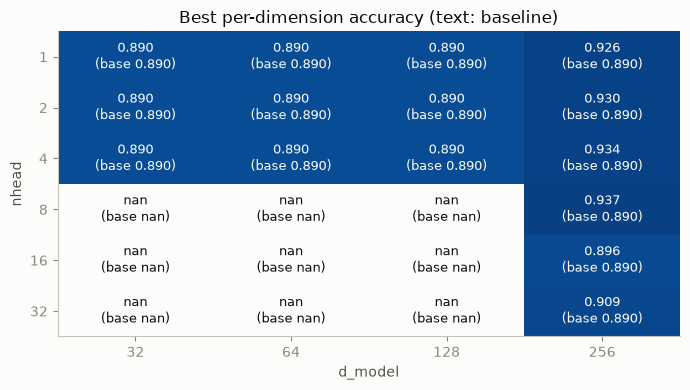

In [8]:
pivot = base_grid.pivot(index="nhead", columns="d_model", values="best_accuracy")
baseline_pivot = base_grid.pivot(index="nhead", columns="d_model", values="baseline_accuracy")

fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor(INK["surface"])
im = ax.imshow(pivot.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(pivot.columns)))
ax.set_xticklabels(pivot.columns)
ax.set_yticks(range(len(pivot.index)))
ax.set_yticklabels(pivot.index)
ax.set_xlabel("d_model")
ax.set_ylabel("nhead")
ax.set_title("Best per-dimension accuracy (text: baseline)", color=INK["primary"])
for i in range(pivot.shape[0]):
    for j in range(pivot.shape[1]):
        acc = pivot.values[i, j]
        base = baseline_pivot.values[i, j]
        color = INK["surface"] if acc > 0.6 else INK["primary"]
        ax.text(j, i, f"{acc:.3f}\n(base {base:.3f})", ha="center", va="center", color=color, fontsize=9)
style_axis(ax)
ax.grid(False)
fig.tight_layout()
plt.show()

Training curves (accuracy vs. epoch) for every swept config, plus the
majority-class baseline as a dashed reference line -- shows whether/when
each config's accuracy actually separates from trivially predicting the
majority class, not just its raw final number.

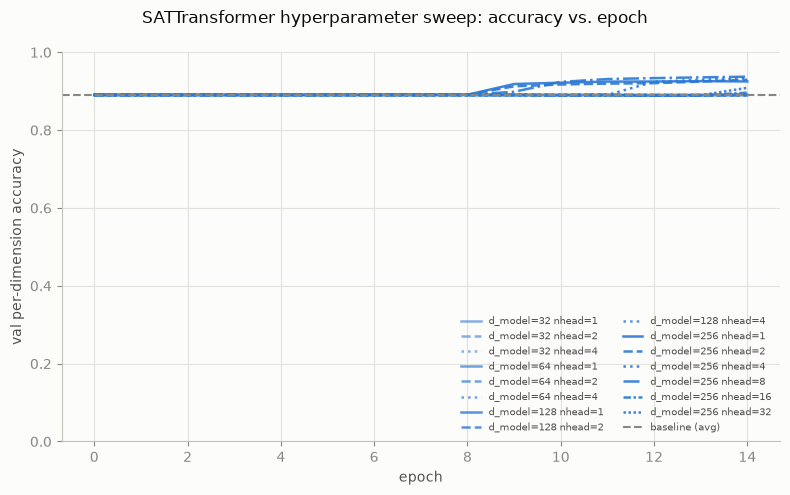

In [9]:
fig, ax = plt.subplots(figsize=(8, 5))
fig.patch.set_facecolor(INK["surface"])
d_models = sorted(base_grid["d_model"].unique())
d_model_shade = {d: v for d, v in zip(d_models, np.linspace(0.35, 1.0, len(d_models)))}
# Custom dash tuples beyond nhead=4: only 4 named linestyles exist in
# matplotlib, and the head-count follow-up extends nhead to 8/16/32.
LINESTYLE = {1: "-", 2: "--", 4: ":", 8: "-.", 16: (0, (3, 1, 1, 1)), 32: (0, (1, 1))}

for _, row in base_grid.iterrows():
    ckpt_dir = Path(row["checkpoint_dir"])
    with open(ckpt_dir / "history.json") as f:
        history = json.load(f)
    hdf = pd.DataFrame(history)
    shade = d_model_shade[row["d_model"]]
    color = tuple(np.array(plt.matplotlib.colors.to_rgb(CATEGORICAL[0])) * shade + np.array([1, 1, 1]) * (1 - shade))
    ax.plot(hdf["epoch"], hdf["accuracy"], color=CATEGORICAL[0], alpha=0.4 + 0.5 * shade,
            linestyle=LINESTYLE[int(row["nhead"])], lw=1.8,
            label=f"d_model={int(row['d_model'])} nhead={int(row['nhead'])}")

ax.axhline(base_grid["baseline_accuracy"].mean(), color=INK["muted"], linestyle="--", lw=1.5, label="baseline (avg)")
ax.set_xlabel("epoch")
ax.set_ylabel("val per-dimension accuracy")
ax.set_ylim(0, 1)
ax.legend(frameon=False, labelcolor=INK["secondary"], fontsize=7, ncol=2, loc="lower right")
style_axis(ax)
fig.suptitle("SATTransformer hyperparameter sweep: accuracy vs. epoch", color=INK["primary"])
fig.tight_layout()
plt.show()

## 3b. Head-count follow-up: is single-head attention the bottleneck?

Only `d_model=256` showed a real lift over the majority-class baseline in
the grid above (92.6-93.4% vs. ~89.05%), but even there
`val_satisfying_completion_rate` stayed at 0% -- the model never produced a
single fully-correct satisfying assignment. Hypothesis: attention *width*
wasn't the limiting factor, head *count* was -- a single attention head can
only form one weighted-average pattern per layer per position, which may not
be enough to simultaneously track multiple relevant clauses. This section
fixes `d_model=256` (the previously-best width) and extends the head-count
axis to `{1,2,4,8,16,32}` (all valid divisors of 256,
`scripts/slurm/sat_nhead_sweep.sbatch`), isolating the head-count effect
directly against the two metrics that actually matter: test NLL and the
fraction of held-out instances the model actually solves.

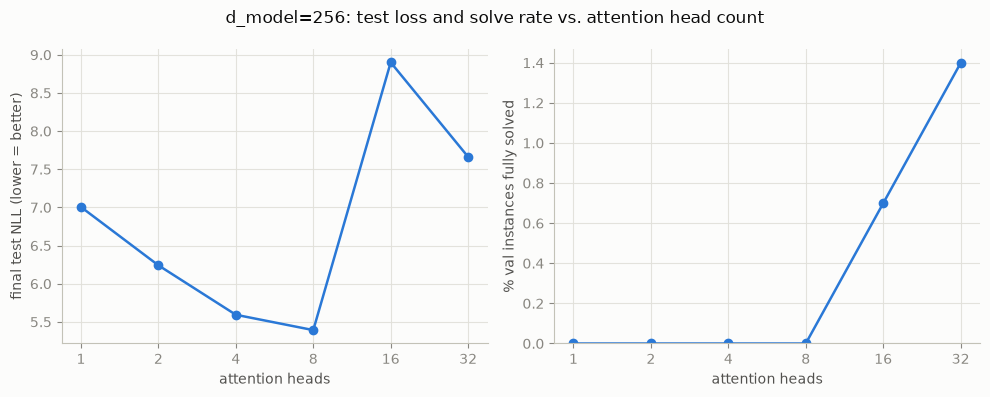

,nhead,baseline_accuracy,best_accuracy,final_nll,final_val_satisfying_completion_rate
9,1,0.890455,0.925871,7.005235,0.000000
14,2,0.890455,0.929504,6.240906,0.000000
19,4,0.890455,0.933504,5.593195,0.000000
24,8,0.890455,0.937303,5.392045,0.000000
45,16,0.890455,0.896317,8.900500,0.006993
50,32,0.890455,0.908678,7.661980,0.013986


In [10]:
d256 = base_grid[base_grid["d_model"] == 256].sort_values("nhead")

fig, axes = plt.subplots(1, 2, figsize=(10, 4))
fig.patch.set_facecolor(INK["surface"])

axes[0].plot(d256["nhead"], d256["final_nll"], marker="o", markersize=6, linewidth=1.8, color=CATEGORICAL[0])
axes[0].set_xscale("log", base=2)
axes[0].set_xticks(d256["nhead"])
axes[0].set_xticklabels(d256["nhead"])
axes[0].set_xlabel("attention heads")
axes[0].set_ylabel("final test NLL (lower = better)")
style_axis(axes[0])

axes[1].plot(d256["nhead"], 100 * d256["final_val_satisfying_completion_rate"], marker="o", markersize=6,
             linewidth=1.8, color=CATEGORICAL[0])
axes[1].set_xscale("log", base=2)
axes[1].set_xticks(d256["nhead"])
axes[1].set_xticklabels(d256["nhead"])
axes[1].set_xlabel("attention heads")
axes[1].set_ylabel("% val instances fully solved")
axes[1].set_ylim(bottom=0)
style_axis(axes[1])

fig.suptitle("d_model=256: test loss and solve rate vs. attention head count", color=INK["primary"])
fig.tight_layout()
plt.show()

d256[["nhead", "baseline_accuracy", "best_accuracy", "final_nll", "final_val_satisfying_completion_rate"]]

## 3c. Depth/width follow-up: does more layers or a bigger MLP help?

The head-count follow-up found `nhead=8` best on raw accuracy/NLL, while
only `nhead=16/32` ever produced a nonzero `val_satisfying_completion_rate`
(0.7%, 1.4%) despite worse accuracy -- and every `nhead>=8` config's
`best_epoch` landed on the final training epoch, suggesting under-training
rather than a settled ceiling. This section fixes `d_model=256, nhead=8`
(the best all-around point so far) and scans `num_layers` ("number of
MLPs" -- each transformer block is one attention sub-layer plus one
feedforward/MLP sub-layer) in `{1,2,4,6}` against `dim_feedforward` (each
block's own MLP hidden width, previously always the implicit default
`4*d_model=1024`) in `{256,512,1024,2048}`: 16 grid points
(`scripts/slurm/sat_mlp_sweep.sbatch`).

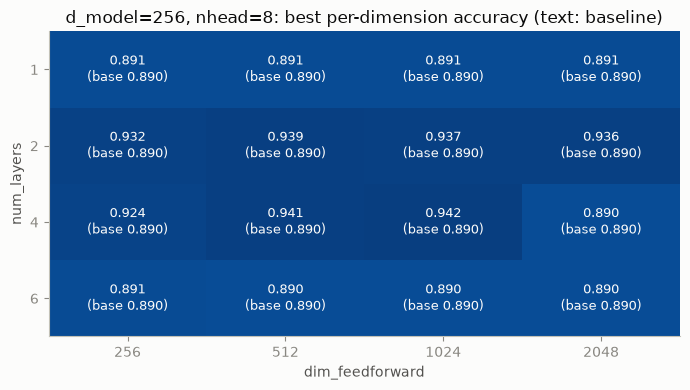

,num_layers,dim_feedforward,baseline_accuracy,best_accuracy,best_epoch,final_nll,final_val_satisfying_completion_rate
25,1,256,0.890455,0.890671,10,9.558412,0.0
26,1,512,0.890455,0.890626,8,9.486550,0.0
27,1,1024,0.890455,0.890767,8,9.472217,0.0
28,1,2048,0.890455,0.890745,8,9.524159,0.0
29,2,256,0.890455,0.932010,14,5.812743,0.0
30,2,512,0.890455,0.938633,14,5.240104,0.0
31,2,1024,0.890455,0.936583,14,5.474613,0.0
32,2,2048,0.890455,0.936119,14,5.488556,0.0
33,4,256,0.890455,0.924387,14,6.554938,0.0
34,4,512,0.890455,0.940767,14,5.159078,0.0


In [11]:
mlp_pivot = mlp_grid.pivot(index="num_layers", columns="dim_feedforward", values="best_accuracy")
mlp_baseline_pivot = mlp_grid.pivot(index="num_layers", columns="dim_feedforward", values="baseline_accuracy")

fig, ax = plt.subplots(figsize=(7, 4))
fig.patch.set_facecolor(INK["surface"])
im = ax.imshow(mlp_pivot.values, cmap="Blues", vmin=0, vmax=1, aspect="auto")
ax.set_xticks(range(len(mlp_pivot.columns)))
ax.set_xticklabels(mlp_pivot.columns)
ax.set_yticks(range(len(mlp_pivot.index)))
ax.set_yticklabels(mlp_pivot.index)
ax.set_xlabel("dim_feedforward")
ax.set_ylabel("num_layers")
ax.set_title("d_model=256, nhead=8: best per-dimension accuracy (text: baseline)", color=INK["primary"])
for i in range(mlp_pivot.shape[0]):
    for j in range(mlp_pivot.shape[1]):
        acc = mlp_pivot.values[i, j]
        base = mlp_baseline_pivot.values[i, j]
        color = INK["surface"] if acc > 0.6 else INK["primary"]
        ax.text(j, i, f"{acc:.3f}\n(base {base:.3f})", ha="center", va="center", color=color, fontsize=9)
style_axis(ax)
ax.grid(False)
fig.tight_layout()
plt.show()

mlp_grid[
    ["num_layers", "dim_feedforward", "baseline_accuracy", "best_accuracy", "best_epoch",
     "final_nll", "final_val_satisfying_completion_rate"]
].sort_values(["num_layers", "dim_feedforward"])

Two failure modes bracket the useful range: `num_layers=1` is too shallow
(every `dim_feedforward` collapses to baseline, ~89.05-89.08%), and
`num_layers=6` combined with `dim_feedforward>=1024` fails to train at all
(`best_epoch=0` -- the model never improves past its random initialization
within 15 epochs, a sign of optimization difficulty at that depth/width
without any learning-rate warmup, not necessarily a capacity problem). The
best config found anywhere in this notebook is `num_layers=4,
dim_feedforward=1024` (accuracy ~94.3%, NLL ~5.0) -- better than any point
in the `(d_model, nhead)` or head-count sweeps. But
`val_satisfying_completion_rate` is exactly 0% for all 16 of these configs,
including the new best -- scaling depth/MLP width pushed the easier
per-token metric further without recovering any of the head-count sweep's
(small) ability to actually complete a satisfying assignment. That
capability so far looks specifically tied to head count, not capacity in
general -- worth testing whether combining more heads *with* this section's
best depth/width closes the gap further, and whether nhead=16/32 simply
need more than 15 epochs to reach their own potential.

## 3d. Attention-rank follow-up: decoupling head count from Q/K rank

Section 3b tied a nonzero `val_satisfying_completion_rate` specifically to
head count, and 3c's own best config (`num_layers=4, dim_feedforward=1024`)
still solved exactly 0% of validation instances. This section asks whether
that gap closes if head count and Q/K rank are allowed to vary
*independently* of each other and of `d_model` -- something ordinary
multi-head attention can't express, since splitting `d_model` into `nhead`
heads fixes each head's Q/K dimension as a side effect of `nhead` alone.

`LowRankSelfAttention`/`LowRankEncoderLayer` (`spin_gnn/sat_transformer.py`)
add a `qk_dim` knob: the *total* (pre-head-split) width of the Q/K
projections, independent of `nhead` and of `d_model`. V and the output
projection always stay at full `d_model`. `qk_dim` can be *below* `d_model`
(genuinely low-rank Q/K) or *above* it (over-parameterized Q/K) -- both are
swept below. When `qk_dim == d_model` the model routes through the exact
same `nn.TransformerEncoderLayer` every earlier section used, so this is a
strict superset of the 3b/3c architecture, not a different model family.

Fixed at 3c's best point (`d_model=256, num_layers=4,
dim_feedforward=1024`), grid: `nhead in {1,2,4,8,16}` x
`qk_dim in {64,128,256,512}` (20 configs, `scripts/slurm/sat_qk_sweep.sbatch`).

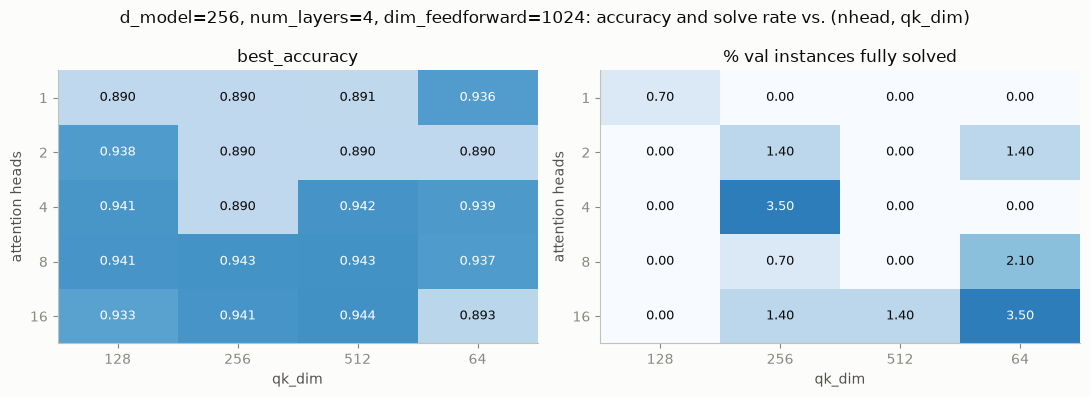

,nhead,qk_dim,baseline_accuracy,best_accuracy,best_epoch,final_nll,final_val_satisfying_completion_rate
11,1,128,0.890455,0.890371,0,9.695670,0.006993
12,1,256,0.890455,0.890372,10,9.888485,0.000000
13,1,512,0.890455,0.890719,11,9.801336,0.000000
10,1,64,0.890455,0.936219,14,5.689391,0.000000
16,2,128,0.890455,0.937715,14,5.520474,0.000000
17,2,256,0.890455,0.890371,0,9.684972,0.013986
18,2,512,0.890455,0.890371,0,9.709815,0.000000
15,2,64,0.890455,0.890372,6,9.675235,0.013986
21,4,128,0.890455,0.940613,14,5.153911,0.000000
22,4,256,0.890455,0.890371,0,9.589307,0.034965


In [12]:
qk_acc_pivot = qk_grid.pivot(index="nhead", columns="qk_dim", values="best_accuracy")
qk_completion_pivot = qk_grid.pivot(index="nhead", columns="qk_dim", values="final_val_satisfying_completion_rate")

fig, axes = plt.subplots(1, 2, figsize=(11, 4))
fig.patch.set_facecolor(INK["surface"])

im0 = axes[0].imshow(qk_acc_pivot.values, cmap="Blues", vmin=0.85, vmax=1.0, aspect="auto")
axes[0].set_xticks(range(len(qk_acc_pivot.columns)))
axes[0].set_xticklabels(qk_acc_pivot.columns)
axes[0].set_yticks(range(len(qk_acc_pivot.index)))
axes[0].set_yticklabels(qk_acc_pivot.index)
axes[0].set_xlabel("qk_dim")
axes[0].set_ylabel("attention heads")
axes[0].set_title("best_accuracy", color=INK["primary"])
for i in range(qk_acc_pivot.shape[0]):
    for j in range(qk_acc_pivot.shape[1]):
        acc = qk_acc_pivot.values[i, j]
        color = INK["surface"] if acc > 0.93 else INK["primary"]
        axes[0].text(j, i, f"{acc:.3f}", ha="center", va="center", color=color, fontsize=9)
style_axis(axes[0])
axes[0].grid(False)

im1 = axes[1].imshow(100 * qk_completion_pivot.values, cmap="Blues", vmin=0, vmax=5, aspect="auto")
axes[1].set_xticks(range(len(qk_completion_pivot.columns)))
axes[1].set_xticklabels(qk_completion_pivot.columns)
axes[1].set_yticks(range(len(qk_completion_pivot.index)))
axes[1].set_yticklabels(qk_completion_pivot.index)
axes[1].set_xlabel("qk_dim")
axes[1].set_ylabel("attention heads")
axes[1].set_title("% val instances fully solved", color=INK["primary"])
for i in range(qk_completion_pivot.shape[0]):
    for j in range(qk_completion_pivot.shape[1]):
        rate = 100 * qk_completion_pivot.values[i, j]
        color = INK["surface"] if rate > 2.5 else INK["primary"]
        axes[1].text(j, i, f"{rate:.2f}", ha="center", va="center", color=color, fontsize=9)
style_axis(axes[1])
axes[1].grid(False)

fig.suptitle("d_model=256, num_layers=4, dim_feedforward=1024: accuracy and solve rate vs. (nhead, qk_dim)", color=INK["primary"])
fig.tight_layout()
plt.show()

qk_grid[["nhead", "qk_dim", "baseline_accuracy", "best_accuracy", "best_epoch", "final_nll",
         "final_val_satisfying_completion_rate"]].sort_values(["nhead", "qk_dim"])


The new global best across every sweep in this notebook is
`nhead=16, qk_dim=512` (accuracy 0.9440, NLL 4.76) -- and unlike every
previous "best accuracy" config in sections 3/3b/3c (all of which had
*exactly* 0% completion), this one also solves 1.4% of validation
instances outright. `qk_dim=512` is *twice* `d_model=256` here -- an
over-parameterized, not low-rank, Q/K -- so the win comes from giving Q/K
more capacity than V/output get, not from compressing it.

The completion-rate heatmap doesn't peak at the same cell as the accuracy
heatmap, though: `nhead=4` and `nhead=16` both hit the grid's highest
completion rate (3.5%) at the grid's *smallest* `qk_dim=64` -- genuinely
low-rank Q/K -- but at accuracy 0.939 and 0.893 respectively, well below
the 16/512 point. The accuracy/completion trade-off from 3b/3c hasn't
disappeared, in other words -- it's just no longer absolute: one corner of
this larger 2-D grid (high `nhead`, high `qk_dim`) is the first point
anywhere in this notebook to land on *both* axes' better half at once.

Four cells in this grid (`(1,128)`, `(2,256)`, `(2,512)`, `(4,256)`)
collapsed to baseline accuracy with `best_epoch=0` and NLL~9.6-9.9 --
the model never escapes its random initialization within 15 epochs, the
same failure signature 3c saw at `num_layers=6`. These four don't share
an obvious pattern across `nhead`/`qk_dim` (unlike 3c's clean depth
cutoff) and each config here is a single training run with a single seed,
so this reads as optimization-instability noise at this learning-rate/
epoch budget rather than a real property of those particular
`(nhead, qk_dim)` combinations -- worth a multi-seed rerun before reading
anything structural into which exact cells failed.

## 4. Play with a trained checkpoint -- no retraining required

Everything below just loads a saved checkpoint from disk and runs cheap
inference. **Edit the parameters in the next cell and re-run from there** to
explore a different config, instance, or generation setting.

In [13]:
from spin_gnn.train_sat_transformer import load_checkpoint

# ---- Parameters: edit and re-run from here, no retraining needed ----
# best_row's own checkpoint_dir, not a reconstructed tag -- newer sweep
# generations encode more than d_model/nhead in their tag (see the
# checkpoint_dir-based base_grid/mlp_grid split above), so rebuilding a path
# from just those two fields would silently point at the wrong checkpoint.
CHECKPOINT_DIR = best_row["checkpoint_dir"]
EXAMPLE_INSTANCE_SEED = 0       # which random instance to render/generate for
GENERATION_TEMPERATURE = 0.0    # 0 = greedy argmax; >0 = sample (try e.g. 0.7)
GENERATION_MAX_NEW_TOKENS = 60  # how many tokens to let the model generate
N_DATASET_EXAMPLES = 2          # how many extra dataset instances to render
# -----------------------------------------------------------------------

model, model_config = load_checkpoint(CHECKPOINT_DIR, device="cpu")
print("loaded checkpoint:", CHECKPOINT_DIR, "->", model_config)

loaded checkpoint: /scratch/users/hshunt/spin_gnn/sat_hparam_sweep/d0256_h16_L04_ff01024_qk0512 -> {'n_vars': 24, 'k': 3, 'alpha': 4.2, 'd_model': 256, 'num_layers': 4, 'nhead': 16, 'dim_feedforward': 1024, 'qk_dim': 512, 'max_len': 2000, 'baseline_accuracy': 0.8904552689480829}


### Dataset examples, rendered human-readable

`spin_gnn.ksat_render` turns the raw `{-1,0,1}` vectors back into CNF-style
text and `x_i=T/F/?` assignment strings.

In [14]:
from spin_gnn.ksat_render import clauses_to_text, trace_to_text

example_cfg = SATConfig(n_vars=model_config["n_vars"], k=model_config["k"], alpha=model_config["alpha"])
for i in range(N_DATASET_EXAMPLES):
    rng = np.random.default_rng(EXAMPLE_INSTANCE_SEED + i)
    clauses = sample_random_ksat(example_cfg, rng)
    trace = solve_with_trace(clauses, example_cfg.n_vars)
    print(f"=== instance {i} (seed={EXAMPLE_INSTANCE_SEED + i}), satisfiable={trace['satisfiable']} ===")
    print(clauses_to_text(clauses))
    print()
    print(trace_to_text(trace["tokens"], trace["step_lengths"], max_steps=4))
    print("...\n")

=== instance 0 (seed=0), satisfiable=True ===
(~x13 | ~x15 | ~x19) &
(x4 | x16 | x19) &
(x13 | x14 | ~x24) &
(~x9 | x14 | x20) &
(~x1 | ~x2 | ~x20) &
(x1 | x9 | x24) &
(x6 | x15 | x19) &
(x9 | ~x16 | x23) &
(~x4 | ~x14 | x20) &
(x10 | x12 | ~x18) &
(x7 | x14 | ~x15) &
(x8 | ~x10 | x17) &
(~x2 | ~x10 | x23) &
(~x2 | ~x18 | x21) &
(x11 | ~x19 | ~x22) &
(x10 | x13 | ~x24) &
(x7 | ~x20 | x22) &
(x2 | x9 | x16) &
(~x10 | ~x11 | ~x12) &
(~x9 | ~x15 | x21) &
(x10 | x18 | ~x19) &
(x2 | x7 | x10) &
(x3 | x4 | x5) &
(x1 | x3 | x20) &
(x4 | ~x8 | x13) &
(x6 | x8 | ~x12) &
(x7 | ~x11 | ~x22) &
(x1 | x16 | ~x20) &
(~x8 | x17 | x21) &
(x7 | ~x20 | x22) &
(~x6 | x8 | x15) &
(x6 | ~x7 | ~x17) &
(x3 | x19 | x23) &
(~x2 | ~x17 | ~x19) &
(x11 | ~x19 | x20) &
(x2 | x6 | ~x13) &
(x2 | x10 | ~x19) &
(~x10 | ~x18 | ~x21) &
(x2 | ~x3 | x7) &
(~x14 | ~x19 | x22) &
(x9 | ~x11 | ~x24) &
(~x1 | x16 | x18) &
(x4 | ~x15 | x21) &
(~x2 | x8 | x17) &
(x7 | x13 | x16) &
(x14 | ~x20 | ~x24) &
(x2 | x17 | ~x20) &
(~x13 |

=== instance 1 (seed=1), satisfiable=False ===
(x11 | ~x12 | x19) &
(~x6 | ~x8 | x21) &
(x3 | x13 | x15) &
(~x8 | ~x11 | ~x18) &
(~x4 | x10 | ~x22) &
(x1 | ~x2 | ~x18) &
(~x3 | x17 | x23) &
(x4 | ~x8 | ~x16) &
(x10 | x11 | x15) &
(~x1 | ~x10 | ~x18) &
(x11 | x15 | ~x19) &
(x8 | x14 | x20) &
(x2 | x4 | x14) &
(~x5 | ~x14 | ~x20) &
(x5 | ~x17 | ~x20) &
(~x7 | x14 | x23) &
(x10 | ~x20 | x24) &
(~x19 | ~x23 | ~x24) &
(x8 | x20 | ~x21) &
(x11 | ~x16 | x24) &
(~x2 | x7 | x16) &
(x8 | ~x20 | ~x23) &
(~x4 | x9 | x19) &
(x10 | ~x13 | ~x24) &
(x3 | ~x9 | ~x14) &
(~x4 | x12 | x16) &
(x2 | x7 | ~x19) &
(~x2 | ~x17 | ~x23) &
(x6 | x20 | ~x23) &
(x2 | x3 | ~x9) &
(x5 | ~x11 | x14) &
(~x7 | ~x11 | ~x14) &
(~x5 | x7 | x9) &
(x4 | x22 | x23) &
(x9 | ~x14 | x16) &
(~x2 | ~x3 | ~x13) &
(x7 | x12 | ~x21) &
(x13 | ~x18 | ~x22) &
(x7 | x16 | ~x17) &
(x5 | ~x16 | ~x23) &
(x9 | x13 | x24) &
(~x12 | x13 | x14) &
(~x1 | x5 | x22) &
(x15 | ~x16 | x20) &
(x1 | x5 | ~x23) &
(~x12 | x18 | ~x22) &
(x1 | ~x9 | ~x19) 

### Model-generated trace vs. the true solver trace, side by side

Prompted with the true initial state (all-unassigned + every original
clause, `spin_gnn.ksat.initial_prompt`) for one instance, the model
autoregressively generates its own continuation. `trace_to_lines` renders
one line per step (assignment, then every non-trivial clause); for the
model's freely-generated sequence there's no externally-known step
grouping, so it's inferred directly from the token stream's own grammar
(`infer_step_lengths` -- if the model doesn't emit assignment/clause tokens
in the expected alternation, that itself shows up as an oddly-grouped
comparison, not a crash). `side_by_side_trace` lines the two traces up in
columns so any divergence is visible immediately, step by step.

In [15]:
from spin_gnn.ksat import initial_prompt
from spin_gnn.ksat_render import side_by_side_trace, trace_to_lines
from spin_gnn.sat_transformer import generate_trace

gen_rng = np.random.default_rng(EXAMPLE_INSTANCE_SEED)
gen_clauses = sample_random_ksat(example_cfg, gen_rng)
gen_trace = solve_with_trace(gen_clauses, example_cfg.n_vars)

prompt = initial_prompt(gen_clauses, example_cfg.n_vars)
generated = generate_trace(
    model, prompt, max_new_tokens=GENERATION_MAX_NEW_TOKENS,
    temperature=GENERATION_TEMPERATURE, rng=np.random.default_rng(0),
)

print(f"=== instance (seed={EXAMPLE_INSTANCE_SEED}), true satisfiable={gen_trace['satisfiable']} ===")
print(clauses_to_text(gen_clauses))
print()

model_lines = trace_to_lines(generated)  # no step_lengths -> inferred from the generated tokens themselves
true_lines = trace_to_lines(gen_trace["tokens"], gen_trace["step_lengths"])
print(side_by_side_trace(model_lines, true_lines, left_title="MODEL-GENERATED", right_title="TRUE SOLVER"))

=== instance (seed=0), true satisfiable=True ===
(~x13 | ~x15 | ~x19) &
(x4 | x16 | x19) &
(x13 | x14 | ~x24) &
(~x9 | x14 | x20) &
(~x1 | ~x2 | ~x20) &
(x1 | x9 | x24) &
(x6 | x15 | x19) &
(x9 | ~x16 | x23) &
(~x4 | ~x14 | x20) &
(x10 | x12 | ~x18) &
(x7 | x14 | ~x15) &
(x8 | ~x10 | x17) &
(~x2 | ~x10 | x23) &
(~x2 | ~x18 | x21) &
(x11 | ~x19 | ~x22) &
(x10 | x13 | ~x24) &
(x7 | ~x20 | x22) &
(x2 | x9 | x16) &
(~x10 | ~x11 | ~x12) &
(~x9 | ~x15 | x21) &
(x10 | x18 | ~x19) &
(x2 | x7 | x10) &
(x3 | x4 | x5) &
(x1 | x3 | x20) &
(x4 | ~x8 | x13) &
(x6 | x8 | ~x12) &
(x7 | ~x11 | ~x22) &
(x1 | x16 | ~x20) &
(~x8 | x17 | x21) &
(x7 | ~x20 | x22) &
(~x6 | x8 | x15) &
(x6 | ~x7 | ~x17) &
(x3 | x19 | x23) &
(~x2 | ~x17 | ~x19) &
(x11 | ~x19 | x20) &
(x2 | x6 | ~x13) &
(x2 | x10 | ~x19) &
(~x10 | ~x18 | ~x21) &
(x2 | ~x3 | x7) &
(~x14 | ~x19 | x22) &
(x9 | ~x11 | ~x24) &
(~x1 | x16 | x18) &
(x4 | ~x15 | x21) &
(~x2 | x8 | x17) &
(x7 | x13 | x16) &
(x14 | ~x20 | ~x24) &
(x2 | x17 | ~x20) &
(~x1

step  MODEL-GENERATED                                               TRUE SOLVER
-------------------------------------------------------------------------------
   0  x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=? x11=? ...  x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   1                                                                x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   2                                                                x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   3                                                                x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   4                                                                x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   5                                                                x1=? x2=? x3=? x4=? x5=? x6=? x7=? x8=? x9=? x10=T x11=? ...
   6                                                              

## Notes / next steps

- **A real bug was caught by the first smoke run, not by the unit tests**:
  `spin_gnn/ksat.py`'s trace-token construction (`np.concatenate` mixing an
  explicit `float32` array with a bare Python-float list) silently upcast
  every trace to `float64`, crashing `SATTransformer`'s `nn.Linear` the
  first time a raw, non-batched trace was fed through the model directly.
  Fixed, with a `tokens.dtype == np.float32` regression check added to
  `tests/test_ksat_solver.py`.
- **A second real bug was caught launching this section's sweep**: capping
  trace length for the training/eval batching path
  (`SATTrainConfig.max_trace_tokens`) didn't cover
  `satisfying_completion_rate`, which iterates the *raw* trace list directly
  -- an over-length trace there crashed every one of the sweep's 12 array
  tasks. Fixed, with a regression test in `tests/test_train_sat_transformer.py`.
- The `max_trace_tokens=2000` cap needed for `O(L^2)`-attention feasibility
  at 10,000 instances systematically drops the hardest (longest,
  deepest-backtracking) instances -- section 3's numbers describe the
  transformer's ability to learn the *easier* end of this distribution, not
  the full one from section 2. A natural follow-up: try increasing the cap
  (fewer instances dropped, more expensive per step) versus keeping more
  training instances at a smaller cap, and see which trades off better.
- Sweeping `alpha` itself (as `spin_gnn/scale_sweep.py` does for the
  kinetic-Ising side of this repo) would show the backtracking-count phase
  transition around the satisfiability threshold directly, rather than just
  the one `alpha=4.2` slice used everywhere above.